In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Import basic libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('bank_transactions_data_2.csv')
df.head()

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance
0,TX000001,AC00128,14.09,4/11/2023 16:29,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21
1,TX000002,AC00455,376.24,6/27/2023 16:44,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91
2,TX000003,AC00019,126.29,7/10/2023 18:16,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35
3,TX000004,AC00070,184.50,5/5/2023 16:32,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06
4,TX000005,AC00411,13.45,10/16/2023 17:51,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40


In [5]:
df.columns

Index(['TransactionID', 'AccountID', 'TransactionAmount', 'TransactionDate',
       'TransactionType', 'Location', 'DeviceID', 'IP Address', 'MerchantID',
       'Channel', 'CustomerAge', 'CustomerOccupation', 'TransactionDuration',
       'LoginAttempts', 'AccountBalance'],
      dtype='object')

In [6]:
# Check info
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11500 entries, 0 to 11499
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   TransactionID        11500 non-null  object 
 1   AccountID            11500 non-null  object 
 2   TransactionAmount    11500 non-null  float64
 3   TransactionDate      11500 non-null  object 
 4   TransactionType      11500 non-null  object 
 5   Location             11500 non-null  object 
 6   DeviceID             11500 non-null  object 
 7   IP Address           11500 non-null  object 
 8   MerchantID           11500 non-null  object 
 9   Channel              11500 non-null  object 
 10  CustomerAge          11500 non-null  int64  
 11  CustomerOccupation   11500 non-null  object 
 12  TransactionDuration  11500 non-null  int64  
 13  LoginAttempts        11500 non-null  int64  
 14  AccountBalance       11500 non-null  float64
dtypes: float64(2), int64(3), object(10)


In [17]:
df.isnull().sum()

TransactionID          0
AccountID              0
TransactionAmount      0
TransactionDate        0
TransactionType        0
Location               0
DeviceID               0
IP Address             0
MerchantID             0
Channel                0
CustomerAge            0
CustomerOccupation     0
TransactionDuration    0
LoginAttempts          0
AccountBalance         0
isFraud                0
dtype: int64

In [19]:
df.duplicated().sum()

0

In [7]:
# Fill missing numeric values with median
for col in df.select_dtypes(include=['float64','int64']):
    df[col].fillna(df[col].median(), inplace=True)

# Fill missing categorical values with mode
for col in df.select_dtypes(include=['object']):
    df[col].fillna(df[col].mode()[0], inplace=True)

In [8]:
# Convert categorical columns to numeric using Label Encoding
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in df.select_dtypes(include=['object']):
    df[col] = le.fit_transform(df[col])

In [9]:
# If dataset doesn't have 'isFraud', create dummy target for demonstration:
if 'isFraud' not in df.columns:
    import numpy as np
    df['isFraud'] = np.random.choice([0,1], size=len(df))  # 0=Not Fraud, 1=Fraud

# Features and Target
X = df.drop('isFraud', axis=1)
y = df['isFraud']

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
# Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

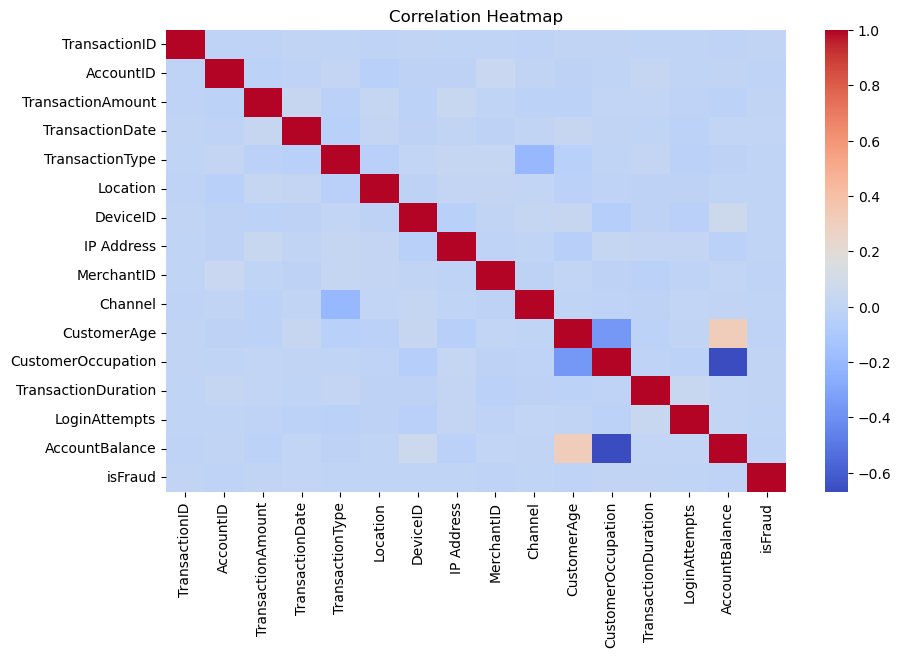

In [12]:
# Correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
plt.title("Correlation Heatmap")
plt.show()

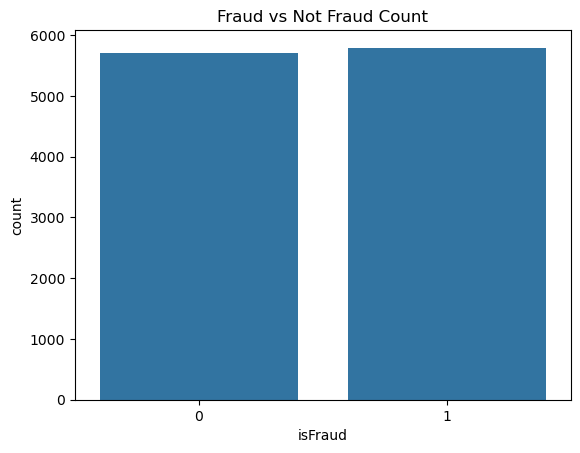

In [13]:
# Fraud Count Plot
sns.countplot(x=y)
plt.title("Fraud vs Not Fraud Count")
plt.show()

In [14]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier

dt_model=DecisionTreeClassifier()
dt_model.fit(X_train,y_train)
dt_pred=dt_model.predict(X_test)
dt_acc=accuracy_score(dt_pred,y_test)
dt_acc


0.4991304347826087

In [15]:
#!pip install xgboost
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Initialize models
models = {
    'RandomForest': RandomForestClassifier(),
    'XGBoost': XGBClassifier(use_label_encoder=False, eval_metric='logloss'),
    'LogisticRegression': LogisticRegression(max_iter=1000)
}

best_model = None
best_score = 0

# Train and compare models
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"{name} Accuracy: {acc}")
    if acc > best_score:
        best_score = acc
        best_model = model

print("\n✅ Best Model:", best_model.__class__.__name__, "with Accuracy:", best_score)

RandomForest Accuracy: 0.4973913043478261
XGBoost Accuracy: 0.49782608695652175
LogisticRegression Accuracy: 0.5082608695652174

✅ Best Model: LogisticRegression with Accuracy: 0.5082608695652174


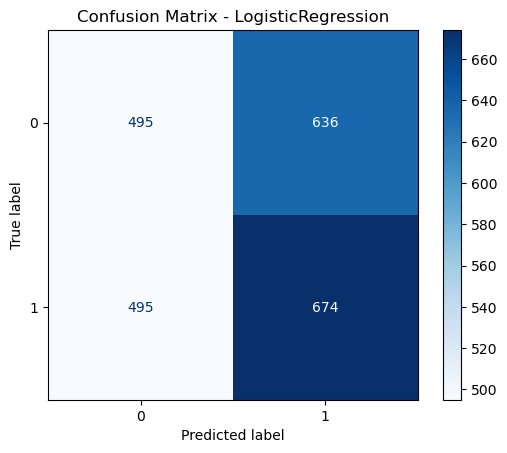

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_preds = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title(f"Confusion Matrix - {best_model.__class__.__name__}")
plt.show()